Cell 1 — Đọc dữ liệu đã làm sạch

In [1]:

# CELL 1: LOAD CLEANED SALES DATA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Xác định thư mục dự án
ROOT = Path.cwd()

if not (ROOT / "data" / "processed" / "sales_clean.csv").exists():
    ROOT = ROOT.parent

# 2. Đường dẫn dữ liệu đã làm sạch
DATA_PATH = ROOT / "data" / "processed" / "sales_clean.csv"

# 3. Đọc file CSV
sales = pd.read_csv(
    DATA_PATH,
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string"
    },
    parse_dates=["InvoiceDate"]
)

# 4. Kiểm tra kích thước
print("===== EDA DATASET =====")
print("Số dòng:", sales.shape[0])
print("Số cột:", sales.shape[1])

# 5. Kiểm tra dữ liệu
print("\n5 dòng đầu tiên:")
display(sales.head())

print("\nThông tin dữ liệu:")
sales.info()

# 6. Kiểm tra doanh thu
print("\nGross Sales:",
      round(sales["Revenue"].sum(), 2))

print("Orders:",
      sales["InvoiceNo"].nunique())


===== EDA DATASET =====
Số dòng: 530104
Số cột: 14

5 dòng đầu tiên:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceCancelled,TransactionType,Revenue,Year,Month,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,Sale_Candidate,15.30,2010,12,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,Sale_Candidate,20.34,2010,12,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,Sale_Candidate,22.00,2010,12,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,Sale_Candidate,20.34,2010,12,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,Sale_Candidate,20.34,2010,12,2010-12



Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 530104 entries, 0 to 530103
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   InvoiceNo         530104 non-null  string        
 1   StockCode         530104 non-null  string        
 2   Description       530104 non-null  str           
 3   Quantity          530104 non-null  int64         
 4   InvoiceDate       530104 non-null  datetime64[us]
 5   UnitPrice         530104 non-null  float64       
 6   CustomerID        397884 non-null  float64       
 7   Country           530104 non-null  str           
 8   InvoiceCancelled  530104 non-null  bool          
 9   TransactionType   530104 non-null  str           
 10  Revenue           530104 non-null  float64       
 11  Year              530104 non-null  int64         
 12  Month             530104 non-null  int64         
 13  YearMonth         530104 non-null  str           


CELL 2: Phân tích doanh thu theo tháng (Monthly Sales Analysis)

In [2]:

# CELL 2: MONTHLY SALES ANALYSIS

# 1. Nhóm dữ liệu theo từng tháng
monthly = (
    sales.groupby("YearMonth", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        UnitsSold=("Quantity", "sum")
    )
)

# 2. Sắp xếp theo thời gian
monthly = monthly.sort_values(
    "YearMonth"
).reset_index(drop=True)

# 3. Tính giá trị trung bình mỗi hóa đơn
monthly["AOV"] = (
    monthly["Revenue"] / monthly["Orders"]
)

# 4. Hiển thị bảng phân tích
print("===== MONTHLY SALES ANALYSIS =====")

display(
    monthly.round({
        "Revenue": 2,
        "AOV": 2
    })
)

# 5. Kiểm tra tổng doanh thu
print("\n===== VALIDATION =====")

print("Gross Sales từ dữ liệu gốc:",
      round(sales["Revenue"].sum(), 2))

print("Gross Sales từ bảng monthly:",
      round(monthly["Revenue"].sum(), 2))

print("Số tháng:", len(monthly))

assert np.isclose(
    sales["Revenue"].sum(),
    monthly["Revenue"].sum()
)

print("MONTHLY VALIDATION PASSED!")


===== MONTHLY SALES ANALYSIS =====


,YearMonth,Revenue,Orders,UnitsSold,AOV
0,2010-12,823746.14,1559,359239,528.38
1,2011-01,691364.56,1086,387785,636.62
2,2011-02,523631.89,1100,283555,476.03
3,2011-03,717639.36,1454,377526,493.56
4,2011-04,537808.62,1246,308815,431.63
5,2011-05,770536.02,1681,395738,458.38
6,2011-06,761739.90,1533,389213,496.89
7,2011-07,719221.19,1475,401759,487.61
8,2011-08,759138.38,1361,421770,557.78
9,2011-09,1058590.17,1837,570820,576.26



===== VALIDATION =====
Gross Sales từ dữ liệu gốc: 10666684.54
Gross Sales từ bảng monthly: 10666684.54
Số tháng: 13
MONTHLY VALIDATION PASSED!


Cell 3 — Vẽ biểu đồ doanh thu theo tháng

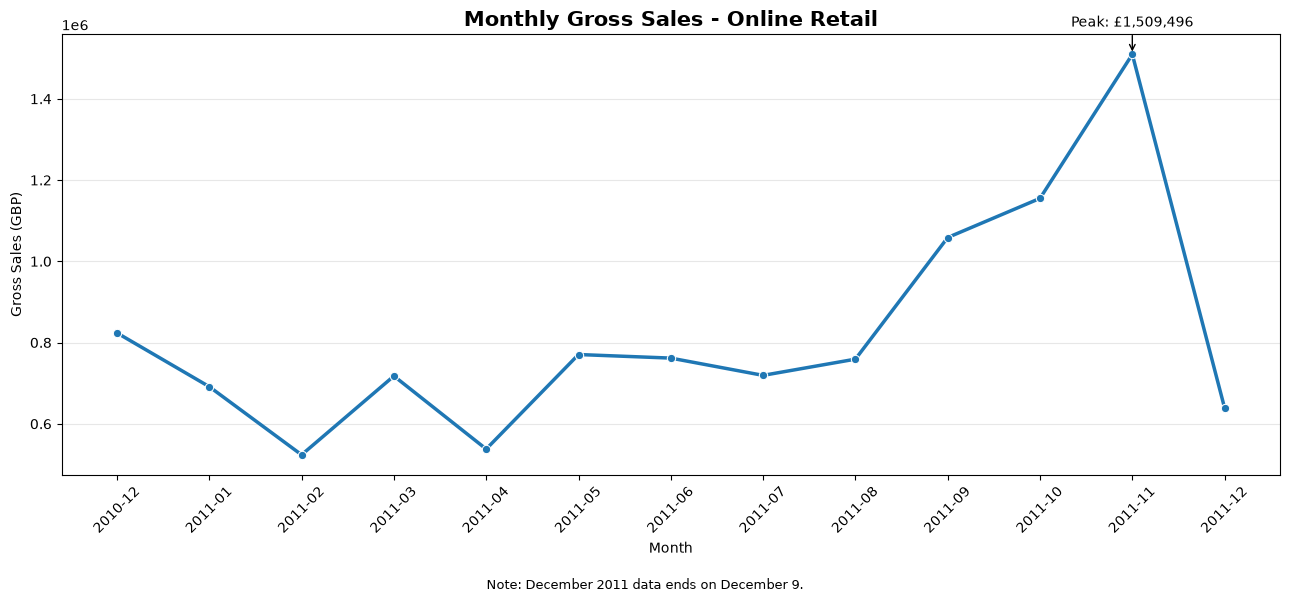

Đã lưu biểu đồ: d:\Projects\ecommerce-sales-analysis\images\monthly_revenue.png


In [3]:

# CELL 3: MONTHLY GROSS SALES CHART

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Sắp xếp dữ liệu theo tháng
monthly_plot = monthly.sort_values("YearMonth").copy()

# 2. Tạo biểu đồ
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_plot,
    x="YearMonth",
    y="Revenue",
    marker="o",
    linewidth=2.5
)

# 3. Tiêu đề và tên trục
plt.title(
    "Monthly Gross Sales - Online Retail",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Gross Sales (GBP)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

# 4. Đánh dấu tháng doanh thu cao nhất
peak = monthly_plot.loc[monthly_plot["Revenue"].idxmax()]

plt.annotate(
    f"Peak: £{peak['Revenue']:,.0f}",
    xy=(peak["YearMonth"], peak["Revenue"]),
    xytext=(0, 20),
    textcoords="offset points",
    ha="center",
    arrowprops=dict(arrowstyle="->")
)

# 5. Chú thích tháng cuối chưa đầy đủ
plt.figtext(
    0.5, 0.01,
    "Note: December 2011 data ends on December 9.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# 6. Lưu biểu đồ
images_dir = ROOT / "images"
images_dir.mkdir(parents=True, exist_ok=True)

chart_path = images_dir / "monthly_revenue.png"

plt.savefig(chart_path, dpi=160, bbox_inches="tight")

plt.show()

print("Đã lưu biểu đồ:", chart_path)


Doanh thu tăng đáng kể từ tháng 8 đến tháng 11/2011. Tháng 11 đạt mức cao nhất khoảng £1,51 triệu, tăng khoảng 30,7% so với tháng 10/2011.

Doanh thu tháng 12 thấp hơn nhiều, nhưng do dữ liệu chỉ kéo dài đến ngày 09/12/2011 nên không thể kết luận doanh nghiệp đang suy giảm doanh thu.

Cell 4: Top 10 Products by Revenue

In [4]:

# CELL 4: TOP 10 PRODUCTS BY REVENUE

# 1. Nhóm theo StockCode và Description
# 2. Tính:
#    Revenue = tổng Revenue
#    UnitsSold = tổng Quantity
top_products = (
    sales.groupby(["StockCode", "Description"], as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        UnitsSold=("Quantity", "sum")
    )
)

# 3. Sắp xếp Revenue giảm dần
top_products = top_products.sort_values(
    "Revenue",
    ascending=False
).reset_index(drop=True)

# 4. Lấy 10 dòng đầu tiên
top_10_products = top_products.head(10)

# 5. Hiển thị bảng kết quả
print("===== TOP 10 PRODUCTS BY REVENUE =====")

display(
    top_10_products.round({
        "Revenue": 2
    })
)

# 6. VALIDATION

print("\n===== PRODUCT ANALYSIS VALIDATION =====")

print("Số sản phẩm trong Top 10:", len(top_10_products))

print(
    "Gross Sales gốc:",
    round(sales["Revenue"].sum(), 2)
)

print(
    "Gross Sales sau khi nhóm:",
    round(top_products["Revenue"].sum(), 2)
)

assert len(top_10_products) == 10

assert np.isclose(
    sales["Revenue"].sum(),
    top_products["Revenue"].sum()
)

print("\nPRODUCT VALIDATION PASSED!")


===== TOP 10 PRODUCTS BY REVENUE =====


,StockCode,Description,Revenue,UnitsSold
0,DOT,DOTCOM POSTAGE,206248.77,706
1,22423,REGENCY CAKESTAND 3 TIER,174484.74,13879
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104340.29,37599
4,47566,PARTY BUNTING,99504.33,18295
5,85099B,JUMBO BAG RED RETROSPOT,94340.05,48474
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
7,M,Manual,78110.27,7224
8,POST,POSTAGE,78101.88,3150
9,23084,RABBIT NIGHT LIGHT,66964.99,30788



===== PRODUCT ANALYSIS VALIDATION =====
Số sản phẩm trong Top 10: 10
Gross Sales gốc: 10666684.54
Gross Sales sau khi nhóm: 10666684.54

PRODUCT VALIDATION PASSED!


Cell 4B: Làm rõ doanh thu sản phẩm

In [5]:

# CELL 4B: PRODUCT-ONLY ANALYSIS

# 1. Các mã không phải sản phẩm đã xác định
non_product_codes = ["DOT", "POST", "M"]

# 2. Loại các mã này khỏi bảng xếp hạng sản phẩm
product_only = top_products.loc[
    ~top_products["StockCode"].isin(non_product_codes)
].copy()

# 3. Lấy Top 10 sản phẩm
top_10_products_only = (
    product_only
    .sort_values("Revenue", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print("===== TOP 10 PRODUCTS (INITIAL FILTER) =====")

display(
    top_10_products_only.round({"Revenue": 2})
)

# 4. Kiểm tra tổng doanh thu của 3 mã đã loại
excluded_revenue = top_products.loc[
    top_products["StockCode"].isin(non_product_codes),
    "Revenue"
].sum()

print("\nDoanh thu 3 mã không phải sản phẩm:",
      round(excluded_revenue, 2))

print("Doanh thu của các mã còn lại:",
      round(product_only["Revenue"].sum(), 2))


===== TOP 10 PRODUCTS (INITIAL FILTER) =====


,StockCode,Description,Revenue,UnitsSold
0,22423,REGENCY CAKESTAND 3 TIER,174484.74,13879
1,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104340.29,37599
3,47566,PARTY BUNTING,99504.33,18295
4,85099B,JUMBO BAG RED RETROSPOT,94340.05,48474
5,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
6,23084,RABBIT NIGHT LIGHT,66964.99,30788
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64952.29,19355
8,84879,ASSORTED COLOUR BIRD ORNAMENT,59094.93,36461
9,79321,CHILLI LIGHTS,54117.76,10306



Doanh thu 3 mã không phải sản phẩm: 362460.92
Doanh thu của các mã còn lại: 10304223.62


In [6]:

# CELL 4C: CHECK UNUSUAL PRODUCT TRANSACTIONS

unusual_transactions = sales.loc[
    sales["StockCode"].isin(["23843", "23166"]),
    [
        "InvoiceNo",
        "InvoiceDate",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "Revenue"
    ]
].copy()

# Sắp xếp theo số lượng giảm dần
unusual_transactions = unusual_transactions.sort_values(
    "Quantity",
    ascending=False
)

print("===== UNUSUAL PRODUCT TRANSACTIONS =====")

display(unusual_transactions.head(10))

# Thống kê từng mã
print("\n===== PRODUCT TRANSACTION SUMMARY =====")

display(
    unusual_transactions.groupby(
        "StockCode",
        as_index=False
    ).agg(
        Rows=("InvoiceNo", "size"),
        Orders=("InvoiceNo", "nunique"),
        TotalUnits=("Quantity", "sum"),
        TotalRevenue=("Revenue", "sum"),
        MaxQuantity=("Quantity", "max")
    ).round(2)
)


===== UNUSUAL PRODUCT TRANSACTIONS =====


,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,Revenue
528623,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
60250,541431,2011-01-18 10:01:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60
278522,561901,2011-07-31 15:42:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,288,1.25,360.00
189748,553607,2011-05-18 10:47:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,240,1.04,249.60
269853,561051,2011-07-24 13:11:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,144,1.04,149.76
196707,554307,2011-05-23 14:59:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,99.84
222665,556917,2011-06-15 13:37:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,99.84
297659,563614,2011-08-18 08:51:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,99.84
514827,580665,2011-12-05 14:06:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,99.84
474819,577669,2011-11-21 10:48:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,99.84



===== PRODUCT TRANSACTION SUMMARY =====


,StockCode,Rows,Orders,TotalUnits,TotalRevenue,MaxQuantity
0,23166,250,247,78033,81700.92,74215
1,23843,1,1,80995,168469.60,80995


4D — Kiểm tra giao dịch trả hàng tương ứng

In [7]:

# CELL 4D: CHECK POTENTIAL REVERSAL TRANSACTIONS

import pandas as pd

# 1. Đọc các cột cần thiết từ dữ liệu gốc
raw_check = pd.read_excel(
    ROOT / "data" / "raw" / "Online Retail.xlsx",
    usecols=[
        "InvoiceNo",
        "StockCode",
        "Quantity",
        "UnitPrice",
        "InvoiceDate"
    ],
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string"
    }
)

# 2. Chuẩn hóa mã
raw_check["InvoiceNo"] = (
    raw_check["InvoiceNo"].str.strip()
)

raw_check["StockCode"] = (
    raw_check["StockCode"].str.strip()
)

# 3. Kiểm tra các giao dịch có số lượng rất lớn
large_transactions = raw_check.loc[
    raw_check["StockCode"].isin(["23843", "23166"])
    & (raw_check["Quantity"].abs() >= 70000)
].copy()

# 4. Tính giá trị giao dịch (có thể âm)
large_transactions["TransactionValue"] = (
    large_transactions["Quantity"]
    * large_transactions["UnitPrice"]
)

# 5. Sắp xếp theo mã và thời gian
large_transactions = large_transactions.sort_values(
    ["StockCode", "InvoiceDate"]
)

print("===== LARGE SALES AND RETURNS =====")

display(large_transactions)

# 6. Tổng hợp giá trị của các giao dịch lớn
print("\n===== LARGE TRANSACTION SUMMARY =====")

display(
    large_transactions.groupby(
        "StockCode",
        as_index=False
    ).agg(
        NetUnits=("Quantity", "sum"),
        NetValue=("TransactionValue", "sum")
    ).round(2)
)


===== LARGE SALES AND RETURNS =====


,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice,TransactionValue
61619,541431,23166,74215,2011-01-18 10:01:00,1.04,77183.6
61624,C541433,23166,-74215,2011-01-18 10:17:00,1.04,-77183.6
540421,581483,23843,80995,2011-12-09 09:15:00,2.08,168469.6
540422,C581484,23843,-80995,2011-12-09 09:27:00,2.08,-168469.6



===== LARGE TRANSACTION SUMMARY =====


,StockCode,NetUnits,NetValue
0,23166,0,0.0
1,23843,0,0.0


Cell 5: Top 10 Products Chart

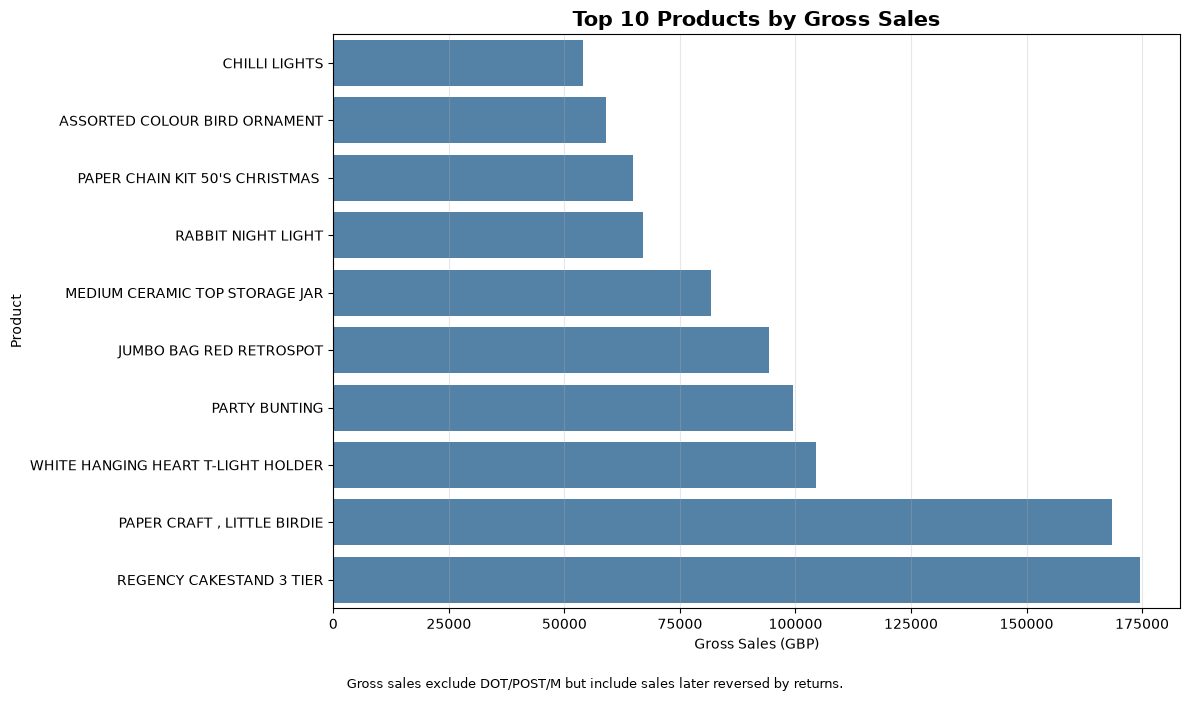

Đã lưu biểu đồ: d:\Projects\ecommerce-sales-analysis\images\top_10_products.png


In [8]:

# CELL 5: TOP 10 PRODUCTS VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Sử dụng Top 10 đã lọc DOT, POST, M
plot_data = top_10_products_only.copy()

# 2. Sắp xếp để vẽ biểu đồ ngang
plot_data = plot_data.sort_values(
    "Revenue",
    ascending=True
)

# 3. Tạo biểu đồ
plt.figure(figsize=(12, 7))

sns.barplot(
    data=plot_data,
    x="Revenue",
    y="Description",
    color="steelblue"
)

# 4. Tiêu đề và nhãn
plt.title(
    "Top 10 Products by Gross Sales",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Gross Sales (GBP)")
plt.ylabel("Product")

plt.grid(axis="x", alpha=0.3)

# 5. Chú thích giao dịch hoàn trả
plt.figtext(
    0.5, 0.01,
    "Gross sales exclude DOT/POST/M but include "
    "sales later reversed by returns.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# 6. Lưu biểu đồ
chart_path = ROOT / "images" / "top_10_products.png"

plt.savefig(
    chart_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("Đã lưu biểu đồ:", chart_path)


REGENCY CAKESTAND 3 TIER có Gross Sales cao nhất: £174.484,74.



PAPER CRAFT, LITTLE BIRDIE đứng thứ hai: £168.469,60.



Biểu đồ trình bày rõ ràng, có tên sản phẩm, trục doanh thu GBP và chú thích về giao dịch hoàn trả.



Đây vẫn là bảng Gross Sales, chưa trừ hoàn trả. Chúng ta đã phát hiện hai giao dịch bán lớn bị hủy tương ứng và sẽ ghi nhận điều đó trong báo cáo cuối.

CELL 6: SALES BY COUNTRY

===== TOP 10 COUNTRIES BY REVENUE =====


,Country,Revenue,Orders,Customers,UnitsSold
0,United Kingdom,9025222.08,18019,3920,4662390
1,Netherlands,285446.34,94,9,200361
2,EIRE,283453.96,288,3,147173
3,Germany,228867.14,457,94,119261
4,France,209715.11,392,87,112103
5,Australia,138521.31,57,9,83901
6,Spain,61577.11,90,30,27940
7,Switzerland,57089.90,54,21,30629
8,Belgium,41196.34,98,25,23237
9,Sweden,38378.33,36,8,36083



===== COUNTRY SALES VALIDATION =====
Số quốc gia: 38
Gross Sales gốc: 10666684.54
Gross Sales theo quốc gia: 10666684.54

COUNTRY VALIDATION PASSED!


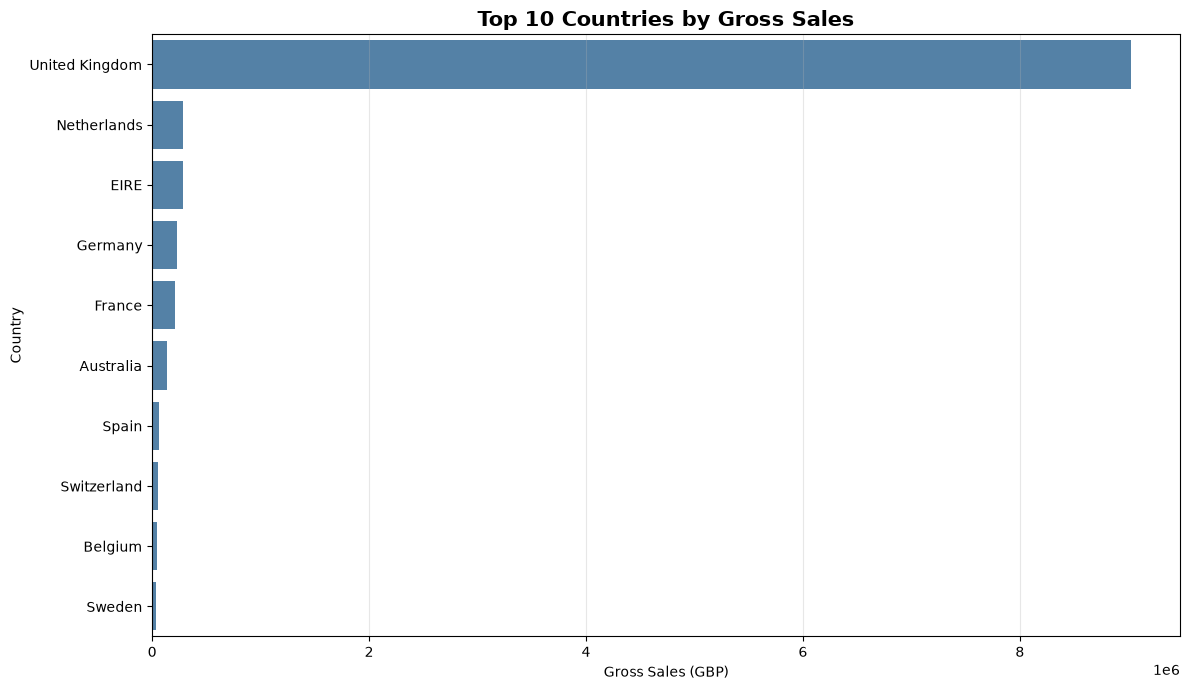


Đã lưu biểu đồ: d:\Projects\ecommerce-sales-analysis\images\top_10_countries.png


In [9]:

# CELL 6: SALES BY COUNTRY

# 1. Nhóm doanh thu theo quốc gia
country_sales = (
    sales.groupby("Country", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Customers=("CustomerID", "nunique"),
        UnitsSold=("Quantity", "sum")
    )
)

# 2. Sắp xếp doanh thu giảm dần
country_sales = country_sales.sort_values(
    "Revenue",
    ascending=False
).reset_index(drop=True)

# 3. Lấy Top 10 quốc gia
top_10_countries = country_sales.head(10).copy()

print("===== TOP 10 COUNTRIES BY REVENUE =====")

display(
    top_10_countries.round({"Revenue": 2})
)

# 4. Kiểm tra dữ liệu
print("\n===== COUNTRY SALES VALIDATION =====")

print("Số quốc gia:", len(country_sales))

print(
    "Gross Sales gốc:",
    round(sales["Revenue"].sum(), 2)
)

print(
    "Gross Sales theo quốc gia:",
    round(country_sales["Revenue"].sum(), 2)
)

assert np.isclose(
    sales["Revenue"].sum(),
    country_sales["Revenue"].sum()
)

print("\nCOUNTRY VALIDATION PASSED!")

# 5. Vẽ biểu đồ Top 10 quốc gia
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_countries,
    x="Revenue",
    y="Country",
    color="steelblue"
)

plt.title(
    "Top 10 Countries by Gross Sales",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Gross Sales (GBP)")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

# 6. Lưu biểu đồ
chart_path = ROOT / "images" / "top_10_countries.png"

plt.savefig(
    chart_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("\nĐã lưu biểu đồ:", chart_path)


Nhận xét kinh doanh: United Kingdom là thị trường chiếm ưu thế, đóng góp khoảng 84,6% Gross Sales. Doanh nghiệp có mức độ tập trung doanh thu cao ở thị trường nội địa. Netherlands và Ireland là hai thị trường tiếp theo nhưng quy mô nhỏ hơn đáng kể.

CELL 7: CUSTOMER ANALYSIS

===== TOP 10 CUSTOMERS BY GROSS SALES =====


,CustomerID,Revenue,Orders,UnitsSold,LastPurchase,AOV
0,14646,280206.02,73,196915,2011-12-08 12:12:00,3838.44
1,18102,259657.30,60,64124,2011-12-09 11:50:00,4327.62
2,17450,194550.79,46,69993,2011-12-01 13:29:00,4229.36
3,16446,168472.50,2,80997,2011-12-09 09:15:00,84236.25
4,14911,143825.06,201,80265,2011-12-08 15:54:00,715.55
5,12415,124914.53,21,77374,2011-11-15 14:22:00,5948.31
6,14156,117379.63,55,57885,2011-11-30 10:54:00,2134.18
7,17511,91062.38,31,64549,2011-12-07 10:12:00,2937.50
8,16029,81024.84,63,40208,2011-11-01 10:27:00,1286.11
9,12346,77183.60,1,74215,2011-01-18 10:01:00,77183.60



===== CUSTOMER ANALYSIS VALIDATION =====
Số khách hàng: 4338
Số dòng có CustomerID: 397884
Số dòng thiếu CustomerID: 132220
Gross Sales từ khách hàng có mã: 8911407.9
Gross Sales tổng hợp theo khách hàng: 8911407.9

CUSTOMER VALIDATION PASSED!


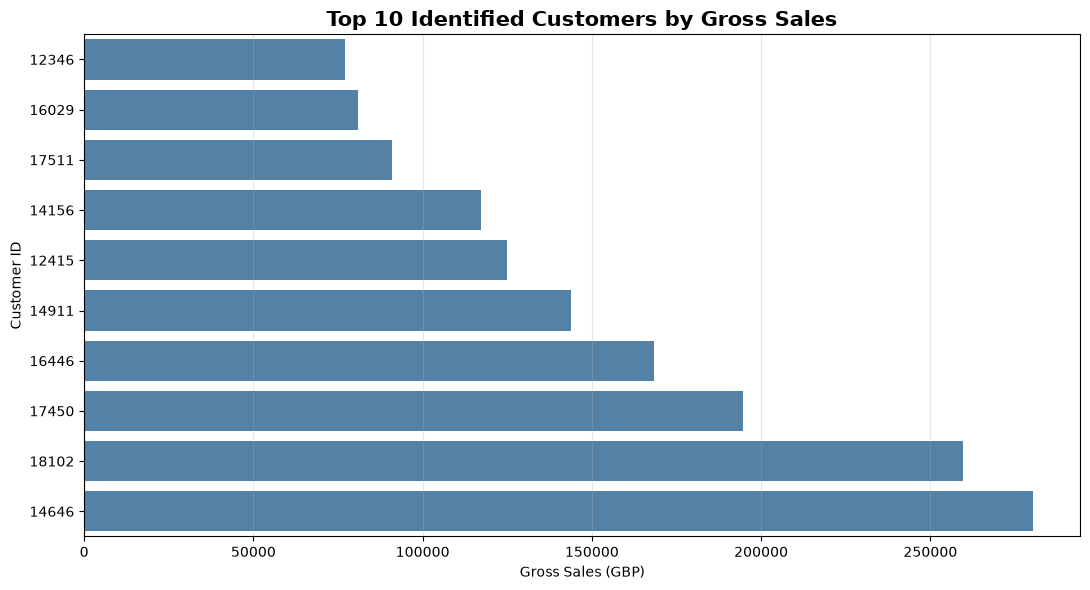


Đã lưu biểu đồ: d:\Projects\ecommerce-sales-analysis\images\top_10_customers.png


In [10]:

# CELL 7: CUSTOMER ANALYSIS

# 1. Chỉ lấy giao dịch có CustomerID
identified_sales = sales.dropna(
    subset=["CustomerID"]
).copy()

# Chuẩn hóa mã khách hàng
identified_sales["CustomerID"] = (
    identified_sales["CustomerID"].astype("Int64")
)

# 2. Tổng hợp theo khách hàng
customer_sales = (
    identified_sales.groupby(
        "CustomerID",
        as_index=False
    )
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        UnitsSold=("Quantity", "sum"),
        LastPurchase=("InvoiceDate", "max")
    )
)

# 3. Tính AOV
customer_sales["AOV"] = (
    customer_sales["Revenue"]
    / customer_sales["Orders"]
)

# 4. Sắp xếp theo doanh thu
customer_sales = customer_sales.sort_values(
    "Revenue",
    ascending=False
).reset_index(drop=True)

# 5. Lấy Top 10 khách hàng
top_10_customers = customer_sales.head(10).copy()

print("===== TOP 10 CUSTOMERS BY GROSS SALES =====")

display(
    top_10_customers.round({
        "Revenue": 2,
        "AOV": 2
    })
)

# 6. Kiểm tra dữ liệu
print("\n===== CUSTOMER ANALYSIS VALIDATION =====")

print("Số khách hàng:",
      len(customer_sales))

print("Số dòng có CustomerID:",
      len(identified_sales))

print("Số dòng thiếu CustomerID:",
      sales["CustomerID"].isna().sum())

print(
    "Gross Sales từ khách hàng có mã:",
    round(identified_sales["Revenue"].sum(), 2)
)

print(
    "Gross Sales tổng hợp theo khách hàng:",
    round(customer_sales["Revenue"].sum(), 2)
)

assert np.isclose(
    identified_sales["Revenue"].sum(),
    customer_sales["Revenue"].sum()
)

print("\nCUSTOMER VALIDATION PASSED!")

# 7. Vẽ biểu đồ Top 10 khách hàng
plot_customers = top_10_customers.copy()

plot_customers["CustomerID"] = (
    plot_customers["CustomerID"].astype(str)
)

plot_customers = plot_customers.sort_values(
    "Revenue",
    ascending=True
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_customers,
    x="Revenue",
    y="CustomerID",
    color="steelblue"
)

plt.title(
    "Top 10 Identified Customers by Gross Sales",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Gross Sales (GBP)")
plt.ylabel("Customer ID")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# 8. Lưu biểu đồ
chart_path = (
    ROOT / "images" / "top_10_customers.png"
)

plt.savefig(
    chart_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("\nĐã lưu biểu đồ:", chart_path)


CELL 8 — Month-over-Month Growth Analysis

===== MONTH-OVER-MONTH GROWTH =====


,YearMonth,Revenue,PreviousRevenue,RevenueChange,MoM_Growth_Pct
0,2010-12,823746.14,NaN,NaN,NaN
1,2011-01,691364.56,823746.14,-132381.58,-16.07
2,2011-02,523631.89,691364.56,-167732.67,-24.26
3,2011-03,717639.36,523631.89,194007.47,37.05
4,2011-04,537808.62,717639.36,-179830.74,-25.06
5,2011-05,770536.02,537808.62,232727.40,43.27
6,2011-06,761739.90,770536.02,-8796.12,-1.14
7,2011-07,719221.19,761739.90,-42518.71,-5.58
8,2011-08,759138.38,719221.19,39917.19,5.55
9,2011-09,1058590.17,759138.38,299451.79,39.45



===== GROWTH SUMMARY =====
Tháng tăng trưởng cao nhất: 2011-05
Tỷ lệ tăng trưởng: 43.27 %

MONTHLY GROWTH VALIDATION PASSED!


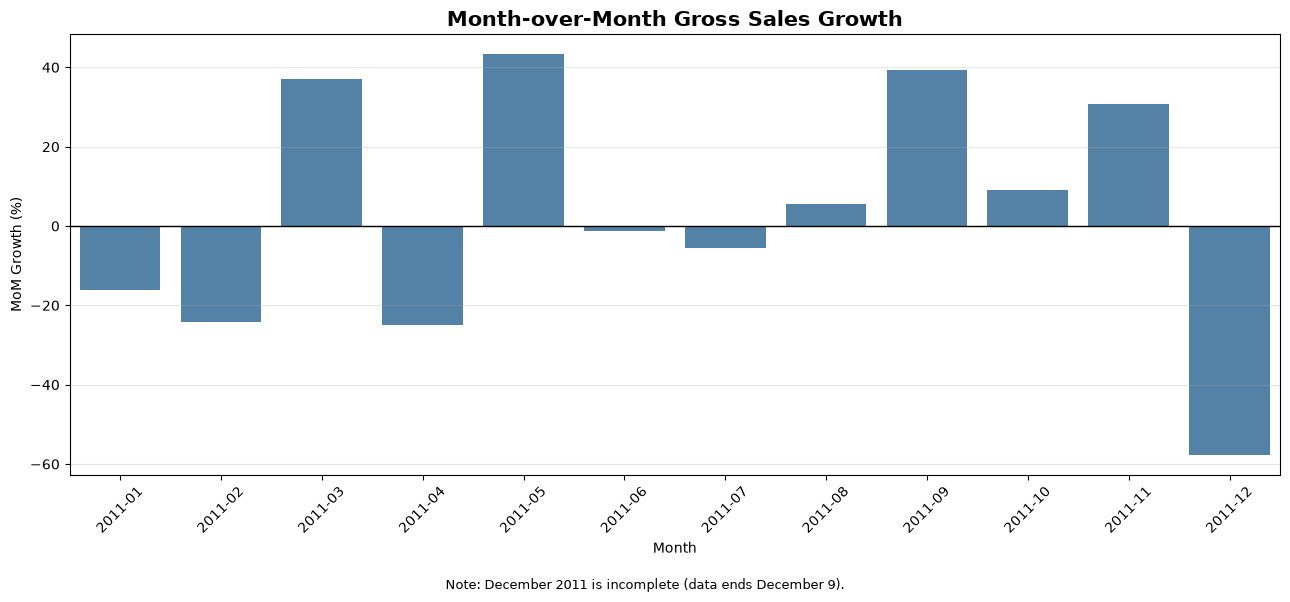


Đã lưu biểu đồ: d:\Projects\ecommerce-sales-analysis\images\monthly_growth.png


In [11]:

# CELL 8: MONTH-OVER-MONTH GROWTH ANALYSIS

# 1. Sao chép và sắp xếp dữ liệu theo tháng
monthly_growth = (
    monthly.sort_values("YearMonth")
    .reset_index(drop=True)
    .copy()
)

# 2. Lấy doanh thu tháng trước
monthly_growth["PreviousRevenue"] = (
    monthly_growth["Revenue"].shift(1)
)

# 3. Tính chênh lệch doanh thu
monthly_growth["RevenueChange"] = (
    monthly_growth["Revenue"]
    - monthly_growth["PreviousRevenue"]
)

# 4. Tính tỷ lệ tăng trưởng MoM (%)
monthly_growth["MoM_Growth_Pct"] = (
    monthly_growth["RevenueChange"]
    / monthly_growth["PreviousRevenue"]
) * 100

# 5. Hiển thị kết quả
print("===== MONTH-OVER-MONTH GROWTH =====")

display(
    monthly_growth[
        [
            "YearMonth",
            "Revenue",
            "PreviousRevenue",
            "RevenueChange",
            "MoM_Growth_Pct"
        ]
    ].round(2)
)

# 6. Xác định tháng tăng trưởng mạnh nhất
valid_growth = monthly_growth.dropna(
    subset=["MoM_Growth_Pct"]
)

best_month = valid_growth.loc[
    valid_growth["MoM_Growth_Pct"].idxmax()
]

print("\n===== GROWTH SUMMARY =====")

print("Tháng tăng trưởng cao nhất:",
      best_month["YearMonth"])

print(
    "Tỷ lệ tăng trưởng:",
    round(best_month["MoM_Growth_Pct"], 2),
    "%"
)

# 7. Kiểm tra dữ liệu
assert len(monthly_growth) == 13

assert np.isclose(
    monthly_growth["Revenue"].sum(),
    sales["Revenue"].sum()
)

print("\nMONTHLY GROWTH VALIDATION PASSED!")

# 8. Vẽ biểu đồ tăng trưởng theo tháng
plt.figure(figsize=(13, 6))

sns.barplot(
    data=valid_growth,
    x="YearMonth",
    y="MoM_Growth_Pct",
    color="steelblue"
)

plt.axhline(y=0, color="black", linewidth=1)

plt.title(
    "Month-over-Month Gross Sales Growth",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("MoM Growth (%)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.figtext(
    0.5, 0.01,
    "Note: December 2011 is incomplete "
    "(data ends December 9).",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# 9. Lưu biểu đồ
chart_path = (
    ROOT / "images" / "monthly_growth.png"
)

plt.savefig(
    chart_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("\nĐã lưu biểu đồ:", chart_path)


Tháng 05/2011 tăng trưởng mạnh nhất, đạt 43,27% so với tháng trước.



Tháng 09/2011 tăng 39,45%, đánh dấu giai đoạn doanh thu vượt £1 triệu.



Tháng 11/2011 đạt doanh thu cao nhất toàn bộ dữ liệu, khoảng £1,51 triệu.



Tháng 12/2011 hiển thị giảm 57,68%, nhưng không thể kết luận doanh thu cả tháng giảm vì dữ liệu chỉ đến ngày 09/12/2011.

CELL 9: EXPORT EDA RESULTS

In [12]:

# CELL 9: EXPORT EDA RESULTS

from pathlib import Path
import pandas as pd
import numpy as np

# 1. Tạo thư mục lưu kết quả
output_dir = ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Danh sách các bảng cần xuất
eda_exports = {
    "monthly_sales.csv": monthly,
    "top_10_products.csv": top_10_products_only,
    "country_sales.csv": country_sales,
    "customer_sales.csv": customer_sales,
    "monthly_growth.csv": monthly_growth
}

# 3. Xuất các file CSV
print("===== EXPORT EDA RESULTS =====")

for filename, dataframe in eda_exports.items():

    file_path = output_dir / filename

    dataframe.to_csv(
        file_path,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        f"{filename}: {len(dataframe)} rows"
    )

# 4. Đọc lại bảng doanh thu theo tháng
monthly_check = pd.read_csv(
    output_dir / "monthly_sales.csv"
)

# 5. Kiểm tra dữ liệu sau khi xuất
print("\n===== EDA EXPORT VALIDATION =====")

print(
    "Gross Sales gốc:",
    round(sales["Revenue"].sum(), 2)
)

print(
    "Gross Sales từ CSV:",
    round(monthly_check["Revenue"].sum(), 2)
)

assert len(monthly_check) == len(monthly)

assert np.isclose(
    monthly_check["Revenue"].sum(),
    sales["Revenue"].sum(),
    rtol=0,
    atol=0.00001
)

# Kiểm tra tất cả file đã được tạo
for filename in eda_exports:
    assert (output_dir / filename).exists()

print("\nEDA EXPORT VALIDATION PASSED!")
print("Đã xuất", len(eda_exports), "file CSV")
print("Thư mục:", output_dir)


===== EXPORT EDA RESULTS =====
monthly_sales.csv: 13 rows
top_10_products.csv: 10 rows
country_sales.csv: 38 rows
customer_sales.csv: 4338 rows
monthly_growth.csv: 13 rows

===== EDA EXPORT VALIDATION =====
Gross Sales gốc: 10666684.54
Gross Sales từ CSV: 10666684.54

EDA EXPORT VALIDATION PASSED!
Đã xuất 5 file CSV
Thư mục: d:\Projects\ecommerce-sales-analysis\data\processed


In [13]:

# PREPARE CSV FOR SQL SERVER IMPORT

sql_ready = sales.copy()

# Chuyển True/False thành 1/0
sql_ready["InvoiceCancelled"] = (
    sql_ready["InvoiceCancelled"].astype(int)
)

# Chuyển CustomerID về số nguyên, giữ giá trị thiếu
sql_ready["CustomerID"] = (
    sql_ready["CustomerID"].astype("Int64")
)

# Chuẩn hóa ngày giờ
sql_ready["InvoiceDate"] = (
    sql_ready["InvoiceDate"].dt.strftime(
        "%Y-%m-%d %H:%M:%S"
    )
)

# Chuẩn hóa số thập phân
for col in ["UnitPrice", "Revenue"]:
    sql_ready[col] = sql_ready[col].map(
        lambda x: f"{x:.4f}"
    )

# Đảm bảo thứ tự 14 cột khớp SQL Server
columns = [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "InvoiceDate", "UnitPrice",
    "CustomerID", "Country", "InvoiceCancelled",
    "TransactionType", "Revenue",
    "Year", "Month", "YearMonth"
]

sql_ready = sql_ready[columns]

# Xuất file riêng, không ghi đè file gốc
sql_path = ROOT / "data" / "processed" / "sales_sql_import.csv"

sql_ready.to_csv(
    sql_path,
    index=False,
    encoding="utf-8",
    lineterminator="\n"
)

print("Đã tạo:", sql_path)
print("Số dòng:", len(sql_ready))
print("Số cột:", len(sql_ready.columns))


Đã tạo: d:\Projects\ecommerce-sales-analysis\data\processed\sales_sql_import.csv
Số dòng: 530104
Số cột: 14
